# 📌 Bölüm 0: Başlangıç Notları ve Simülasyon (Orijinal Kodlar)
Aşağıdaki kod hücreleri Merkezi Limit Teoremi (Central Limit Theorem) için hazırlanan ilk notları, üstel dağılımdan üretilen ana kütleyi ve örneklem ortalamalarının simülasyonunu içermektedir.


In [6]:
# Central Limit Theorem
# Verinin dağılımı nasıl olursa olsun: Yeterinde büüyk farklı örneklemler alırsanız
# Bu örneklem ortalamasını normal dağılım gösterir.

2.016486402619456
1.9990201264344145


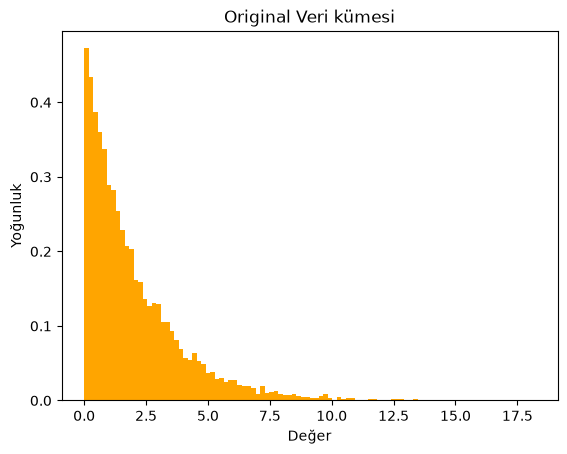

In [8]:
import numpy as np
import matplotlib.pyplot as plt

population = np.random.exponential(scale = 2, size = 10000)

population_mean = np.mean(population)
population_std = np.std(population)

print(population_mean)
print(population_std)

plt.hist(population, bins = 100, color = "orange", density = True)
plt.title("Original Veri kümesi")
plt.xlabel("Değer")
plt.ylabel("Yoğunluk")
plt.show()

In [14]:
# 10000'lik pöpulasyondan 
sample_mean = []

for _ in range(1000):
    sample = np.random.choice(population, size = 50)
    sample_mean.append(np.mean(sample))

#print(len(sample_mean))
#print(sample_mean)

np_samples = np.array(sample_mean)
print("Sample Mean = ", np.mean(np_samples))

Sample Mean =  2.0008715692520047


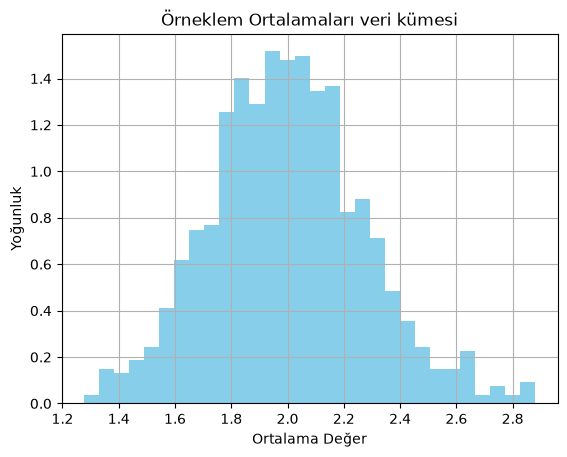

In [15]:
plt.hist(sample_mean, bins = 30, color = "skyblue", density= True)
plt.title("Örneklem Ortalamaları veri kümesi")
plt.xlabel("Ortalama Değer")
plt.ylabel("Yoğunluk")
plt.grid(True)
plt.show()

---
# 📚 MERKEZİ LİMİT TEOREMİ (CENTRAL LIMIT THEOREM - CLT)
### İstatistiğin En Temel ve Güçlü Teoremi - Kapsamlı Teori ve Uygulama Rehberi

---

## 📌 1. Giriş ve Sezgisel Açıklama

**Merkezi Limit Teoremi (Central Limit Theorem - CLT)**, istatistiğin, veri biliminin ve modern çıkarımsal istatistiğin (inferential statistics) bel kemiğidir.

### 🌟 Teoremin Ana Fikri Nedir?
> **Ana Kütle Dağılımı Ne Olursa Olsun** (ister sağa çarpık üstel, ister düzgün, ister çift tepeli, ister ayrık):
> Bu ana kütleden bağımsız ve özdeş dağılmış (**i.i.d. - independent and identically distributed**) yeterince büyük ($n \ge 30$) rastgele örneklemler çekilip bu örneklemlerin **ortalamaları ($\bar{X}$)** hesaplandığında; bu örneklem ortalamalarının oluşturduğu yeni dağılım **Normal (Gauss / Çan Eğrisi) Dağılımına** yakınsar!

---

### 🔍 Büyük Sayılar Yasası (LLN) ile Merkezi Limit Teoremi (CLT) Farkı

| Özellik | Büyük Sayılar Yasası (Law of Large Numbers - LLN) | Merkezi Limit Teoremi (Central Limit Theorem - CLT) |
| :--- | :--- | :--- |
| **Odak Noktası** | Örneklem ortalamasının **tek bir değere** yakınsaması. | Örneklem ortalamasının **dağılımının şekli ve yayılımı**. |
| **Matematiksel İfade** | $\lim_{n \to \infty} P(|\bar{X}_n - \mu| > \epsilon) = 0$ | $\sqrt{n}(\bar{X}_n - \mu) \xrightarrow{d} \mathcal{N}(0, \sigma^2)$ |
| **Sezgisel Anlamı** | "Daha çok zar atarsan ortalaman kesinlikle 3.5'e yaklaşır." | "Örneklem ortalamalarının oluşturduğu grafik bir çan eğrisi çizer." |
| **Kullanım Alanı** | Tutarlılık (Consistency) ve olasılık tahminleri. | Güven aralıkları, hipotez testleri ($Z, t$), hata marjı hesabı. |


---
## 📐 2. Matematiksel Formülasyon ve Standart Hata ($\text{SE}$)

Ana kütlemizin ortalaması $\mu$ ve varyansı $\sigma^2$ olsun (ana kütlenin normal dağılması **gerekmez**, sonlu varyansa sahip olması yeterlidir):

1. **Örneklem Ortalamasının Beklenen Değeri:**
   $$E[\bar{X}] = \mu_{\bar{X}} = \mu$$
   *(Örneklem ortalaması, ana kütle ortalamasının yansız / unbiased bir tahmincisidir.)*

2. **Örneklem Ortalamasının Varyansı ve Standart Hatası ($\text{Standard Error - SE}$):**
   $$\text{Var}(\bar{X}) = \sigma_{\bar{X}}^2 = \frac{\sigma^2}{n}$$
   $$\text{SE}(\bar{X}) = \sigma_{\bar{X}} = \frac{\sigma}{\sqrt{n}}$$

3. **Asimptotik Dağılım:**
   $$\bar{X} \sim \mathcal{N}\left( \mu, \frac{\sigma^2}{n} \right) \quad \text{veya standartlaştırılmış biçimiyle:} \quad Z = \frac{\bar{X} - \mu}{\frac{\sigma}{\sqrt{n}}} \sim \mathcal{N}(0, 1)$$

> 💡 **Kritik Çıkarım ($1/\sqrt{n}$ Kuralı):**
> - Örneklem büyüklüğü $n$ arttıkça ortalamaların dağılımı **daralır** (standart hata küçülür).
> - Örneklem büyüklüğünü $4$ katına çıkarırsanız, tahmin hatanız **yarıya iner** ($\sqrt{4}=2$).
> - $n \ge 30$ kuralı: Genelde $n \ge 30$ olduğunda CLT mükemmel çalışır; simetrik dağılımlarda $n=5-10$ bile yeterlidir.


---
## 💻 3. Python Ortam Hazırlığı ve Kütüphaneler


In [ ]:
from IPython.display import display
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# Görselleştirme ve stil ayarları
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['figure.dpi'] = 110

# Tekrarlanabilirlik için tohum belirle
np.random.seed(42)
print("✅ Gerekli kütüphaneler başarıyla yüklendi ve grafik ortamı hazırlandı.")


---
## 🎨 4. CLT Görsel Matrisi: 4 Farklı Ekstrem Dağılımın Çan Eğrisine Dönüşümü (4x4 Grid)

Aşağıdaki simülasyonda 4 tamamen farklı ana kütle dağılımını ele alıyoruz:
1. **Düzgün Dağılım (Uniform):** Tamamen düz / köşeli.
2. **Üstel Dağılım (Exponential):** Aşırı sağa çarpık (bekleme süreleri).
3. **Çift Tepeli Dağılım (Bimodal):** İki farklı tepesi olan multimodal dağılım.
4. **Log-Normal Dağılım:** Uzun kuyruklu, asimetrik dağılım.

Farklı örneklem boyutları ($n = 1, 5, 30, 100$) için 5.000 kez örneklem çekip ortalamaların histogramını çiziyoruz:


In [ ]:
# 1. Dört farklı ana kütle dağılımı oluştur
N_POP = 100_000

pop_uniform = np.random.uniform(low=0, high=10, size=N_POP)
pop_exponential = np.random.exponential(scale=2.0, size=N_POP)
# Bimodal (İki tepe: %50 N(2, 0.5^2), %50 N(8, 0.8^2))
pop_bimodal = np.concatenate([
    np.random.normal(loc=2, scale=0.5, size=N_POP // 2),
    np.random.normal(loc=8, scale=0.8, size=N_POP // 2)
])
pop_lognormal = np.random.lognormal(mean=0, sigma=0.8, size=N_POP)

populations = {
    "1. Düzgün (Uniform)": (pop_uniform, "#3498db"),
    "2. Üstel (Exponential - Sağa Çarpık)": (pop_exponential, "#e67e22"),
    "3. Çift Tepeli (Bimodal)": (pop_bimodal, "#9b59b6"),
    "4. Log-Normal (Ağır Kuyruk)": (pop_lognormal, "#e74c3c")
}

sample_sizes = [1, 5, 30, 100]
num_simulations = 5000

fig, axes = plt.subplots(len(populations), len(sample_sizes), figsize=(16, 12), sharey=False)
fig.suptitle("🧬 Merkezi Limit Teoremi (CLT) Görsel Matrisi: Farklı Dağılımların Normalleşmesi", fontsize=16, fontweight='bold', y=0.99)

for row_idx, (name, (pop, color)) in enumerate(populations.items()):
    pop_mean = np.mean(pop)
    pop_std = np.std(pop)
    
    for col_idx, n in enumerate(sample_sizes):
        ax = axes[row_idx, col_idx]
        
        # n boyutunda num_simulations adet örneklem ortalaması üret
        if n == 1:
            means = np.random.choice(pop, size=num_simulations, replace=True)
        else:
            samples = np.random.choice(pop, size=(num_simulations, n), replace=True)
            means = np.mean(samples, axis=1)
            
        # Histogram ve KDE çiz
        sns.histplot(means, kde=True, stat="density", color=color, ax=ax, bins=35, alpha=0.6)
        
        # Teorik Normal eğrisi (n >= 5 için)
        if n > 1:
            se = pop_std / np.sqrt(n)
            x_curve = np.linspace(means.min(), means.max(), 200)
            y_curve = stats.norm.pdf(x_curve, loc=pop_mean, scale=se)
            ax.plot(x_curve, y_curve, 'r--', linewidth=1.5, label='Teorik Normal')
            
        if row_idx == 0:
            ax.set_title(f"Örneklem Boyutu: n = {n}", fontsize=12, fontweight='bold')
        if col_idx == 0:
            ax.set_ylabel(name, fontsize=10, fontweight='bold')
        else:
            ax.set_ylabel("")
            
        ax.tick_params(labelsize=8)
        if row_idx == 0 and col_idx == len(sample_sizes)-1:
            ax.legend(fontsize=8, loc='upper right')

plt.tight_layout()
plt.show()


---
## 📉 5. Standart Hata ($\text{SE}$) ve $1/\sqrt{n}$ Daralma Kuralı Analizi

Örneklem boyutu $n$ büyüdükçe örneklem ortalamalarının standart sapması (Standart Hata):
$$\text{SE} = \frac{\sigma}{\sqrt{n}}$$
kuralına göre küçülür. Bu durum tahminlerimizin ne kadar güvenilir ve hassas hale geldiğini gösterir.


In [ ]:
# n değerleri ve Standart Hata karşılaştırması
n_values = [5, 10, 25, 50, 100, 250, 500, 1000]
pop_exp = np.random.exponential(scale=4.0, size=200_000)  # mu = 4, sigma = 4
mu_true = 4.0
sigma_true = 4.0

records = []
for n in n_values:
    # 5000 adet örneklem ortalaması
    sim_samples = np.random.choice(pop_exp, size=(5000, n), replace=True)
    sim_means = np.mean(sim_samples, axis=1)
    
    sim_se = np.std(sim_means, ddof=1)
    theo_se = sigma_true / np.sqrt(n)
    error_diff = abs(sim_se - theo_se)
    
    records.append({
        "Örneklem Boyutu (n)": n,
        "Teorik SE (sigma/sqrt(n))": round(theo_se, 4),
        "Simüle Edilen SE": round(sim_se, 4),
        "Mutlak Fark": round(error_diff, 5),
        "%95 Hata Marjı (1.96*SE)": round(1.96 * theo_se, 4)
    })

df_se = pd.DataFrame(records)
print("📊 Örneklem Boyutu (n) ile Standart Hata Arasındaki İlişki Tablosu:")
display(df_se)

# Standart Hatanın Küçülmesini Çiz
plt.figure(figsize=(10, 5))
plt.plot(df_se["Örneklem Boyutu (n)"], df_se["Teorik SE (sigma/sqrt(n))"], 'o-', color='#2980b9', linewidth=2.5, label='Teorik Standart Hata (SE)')
plt.plot(df_se["Örneklem Boyutu (n)"], df_se["Simüle Edilen SE"], 's--', color='#e74c3c', linewidth=1.5, label='Simülasyon SE')
plt.title("Örneklem Boyutu Arttıkça Standart Hatanın Küçülmesi (1 / √n Yasası)", fontsize=13, fontweight='bold')
plt.xlabel("Örneklem Büyüklüğü (n)", fontsize=11)
plt.ylabel("Standart Hata (SE)", fontsize=11)
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend(fontsize=11)
plt.show()


---
## 💼 6. Gerçek Hayat Vaka Analizi 1: E-Ticaret Ortalama Sepet Tutarı (AOV) ve Gelir Tahmini

### 🛒 Problem Senaryosu:
Bir e-ticaret platformunda müşteri harcama tutarları **aşırı sağa çarpıktır** (Müşterilerin %80'i 20-100 TL harcarken, kurumsal veya toptan alıcılar 5.000 - 50.000 TL harcamaktadır).
- Platformun genel sepet verisi normal **dağılmaz**.
- Ancak rastgele seçilen $n=100$ müşterilik grupların ortalama sepet tutarları **CLT sayesinde Normal dağılır**.
- Bu sayede parametrik **%95 Güven Aralığı (Confidence Interval)** ve hipotez testleri güvenle uygulanabilir!


In [ ]:
# E-Ticaret Sepet Tutarı (Log-Normal dağılımlı sağa çarpık veri)
np.random.seed(123)
pop_orders = np.random.lognormal(mean=4.2, sigma=1.1, size=100_000) + 15  # Min 15 TL harcama

gercek_pop_ortalama = np.mean(pop_orders)
gercek_pop_std = np.std(pop_orders)

print(f"📦 Gerçek Ana Kütle Ortalama Sepet Tutarı: {gercek_pop_ortalama:.2f} TL")
print(f"📦 Gerçek Ana Kütle Standart Sapması: {gercek_pop_std:.2f} TL")

# 100 müşterilik bir örneklem seçip %95 Güven Aralığı kuralım
n_sample = 100
sample_orders = np.random.choice(pop_orders, size=n_sample, replace=False)

sample_mean = np.mean(sample_orders)
sample_se = stats.sem(sample_orders)  # stats.sem = s / sqrt(n)
ci_lower, ci_upper = stats.t.interval(confidence=0.95, df=n_sample-1, loc=sample_mean, scale=sample_se)

print(f"\n🔍 Tekil 100 Müşterilik Örneklem Analizi:")
print(f"   Örneklem Ortalaması: {sample_mean:.2f} TL")
print(f"   Standart Hata (SE): {sample_se:.2f} TL")
print(f"   %95 Güven Aralığı: [{ci_lower:.2f} TL - {ci_upper:.2f} TL]")

# Görselleştirme: Orijinal Sağa Çarpık Veri vs Örneklem Ortalamaları Dağılımı
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 1. Orijinal Harcama Dağılımı
sns.histplot(pop_orders[pop_orders < 800], bins=60, color='#e67e22', kde=True, ax=axes[0])
axes[0].set_title("Orijinal Müşteri Harcamaları (Aşırı Çarpık)", fontsize=12, fontweight='bold')
axes[0].set_xlabel("Sipariş Tutarı (TL)")
axes[0].set_ylabel("Frekans")

# 2. 2000 Farklı Örneklemin (n=100) Ortalamaları
sim_means = [np.mean(np.random.choice(pop_orders, size=100, replace=False)) for _ in range(2000)]
sns.histplot(sim_means, bins=35, color='#2ecc71', kde=True, stat="density", ax=axes[1])
axes[1].axvline(gercek_pop_ortalama, color='red', linestyle='--', linewidth=2, label=f'Gerçek Ortalama ({gercek_pop_ortalama:.1f} TL)')
axes[1].axvline(ci_lower, color='navy', linestyle=':', label='%95 GA Alt/Üst')
axes[1].axvline(ci_upper, color='navy', linestyle=':')
axes[1].set_title("100'lük Grupların Ortalama Sepet Tutarları (CLT - Gauss)", fontsize=12, fontweight='bold')
axes[1].set_xlabel("Örneklem Ortalama Tutarı (TL)")
axes[1].legend()

plt.tight_layout()
plt.show()


---
## 🏭 7. Gerçek Hayat Vaka Analizi 2: Fabrika Seri Üretim & Kalite Kontrol (Six Sigma)

Bir fabrikada üretilen çelik millerin çapı nominal $50\text{ mm}$'dir.
- Tekil parçaların standart sapması $\sigma = 2\text{ mm}$'dir.
- Müşterinin kabul kriteri: Rastgele seçilen $n=36$ parçalık koli ortalamasının $49.5\text{ mm}$ ile $50.5\text{ mm}$ arasında olmasıdır.
- **Soru:** Gönderilen bir kolinin kabul edilme olasılığı nedir?


In [ ]:
mu_part = 50.0   # mm
sigma_part = 2.0 # mm
n_box = 36       # koli adedi

# Standart Hata
se_box = sigma_part / np.sqrt(n_box)  # 2 / 6 = 0.333 mm

LSL = 49.5  # Alt Spesifikasyon Limiti
USL = 50.5  # Üst Spesifikasyon Limiti

# Z skorları
z_lower = (LSL - mu_part) / se_box
z_upper = (USL - mu_part) / se_box

prob_acceptance = stats.norm.cdf(z_upper) - stats.norm.cdf(z_lower)

print(f"⚙️ Fabrika Kalite Kontrol Analizi:")
print(f"   Koli Standart Hatası (SE): {se_box:.4f} mm")
print(f"   Z_alt = {z_lower:.2f}, Z_üst = {z_upper:.2f}")
print(f"   Kolinin Kabul Edilme Olasılığı: %{prob_acceptance * 100:.2f}")

# Grafik
x_plot = np.linspace(48.5, 51.5, 500)
y_plot = stats.norm.pdf(x_plot, loc=mu_part, scale=se_box)

plt.figure(figsize=(10, 4.5))
plt.plot(x_plot, y_plot, color='#2c3e50', linewidth=2, label=f'Koli Ortalamaları Dağılımı N(50, {se_box:.2f}²)')
plt.fill_between(x_plot, y_plot, where=((x_plot >= LSL) & (x_plot <= USL)), color='#27ae60', alpha=0.4, label=f'Kabul Bölgesi (%{prob_acceptance*100:.1f})')
plt.axvline(LSL, color='red', linestyle='--', label=f'Alt Limit ({LSL} mm)')
plt.axvline(USL, color='red', linestyle='--', label=f'Üst Limit ({USL} mm)')
plt.title("Seri Üretim Koli Ortalamalarının Kabul Olasılığı (CLT Analizi)", fontsize=13, fontweight='bold')
plt.xlabel("Ortalama Çap (mm)")
plt.ylabel("Olasılık Yoğunluğu")
plt.legend()
plt.show()


---
## 🧪 8. Normallik Doğrulaması: Q-Q Plot ve Shapiro-Wilk Testi

Örneklem ortalamalarımızın gerçekten Normal dağılıma uyup uymadığını iki yöntemle test ediyoruz:
1. **Q-Q Plot (Quantile-Quantile):** Noktalar kırmızı $45^\circ$ doğrusu üzerindeyse dağılım normaldir.
2. **Shapiro-Wilk ve Jarque-Bera Testleri:** $p\text{-value} > 0.05$ ise "Veri normal dağılmaktadır" $\mathcal{H}_0$ hipotezi reddedilemez.


In [ ]:
# Üstel popülasyondan n=50 için 1000 örneklem ortalaması
exp_pop = np.random.exponential(scale=3.0, size=50_000)
sample_means_test = [np.mean(np.random.choice(exp_pop, size=50)) for _ in range(1000)]

# Normallik Testleri
shapiro_stat, shapiro_p = stats.shapiro(sample_means_test[:500]) # 500 örneklem ile
jb_stat, jb_p = stats.jarque_bera(sample_means_test)

print("🔬 İstatistiksel Normallik Test Sonuçları:")
print(f"   Shapiro-Wilk Testi: İstatistik = {shapiro_stat:.4f}, p-değeri = {shapiro_p:.4f}")
print(f"   Jarque-Bera Testi:  İstatistik = {jb_stat:.4f}, p-değeri = {jb_p:.4f}")

if shapiro_p > 0.05:
    print("   👉 Karar: p > 0.05 olduğundan örneklem ortalamalarının NORMAL dağıldığı doğrulanmıştır!")
else:
    print("   👉 Karar: Normallikten hafif sapma bulunmaktadır.")

# Q-Q Plot
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Histogram
sns.histplot(sample_means_test, kde=True, color='#8e44ad', stat="density", ax=axes[0])
axes[0].set_title("Örneklem Ortalamaları Dağılımı", fontsize=12, fontweight='bold')

# Q-Q Plot
stats.probplot(sample_means_test, dist="norm", plot=axes[1])
axes[1].get_lines()[0].set_color('#8e44ad')
axes[1].get_lines()[0].set_markersize(4)
axes[1].get_lines()[1].set_color('red')
axes[1].get_lines()[1].set_linewidth(2)
axes[1].set_title("Normal Q-Q Plot (Doğrulama)", fontsize=12, fontweight='bold')

plt.tight_layout()
plt.show()


---
## 📋 9. Özet ve Formül Rehberi (Cheat Sheet)

| Kavram | Formül / Tanım | Açıklama |
| :--- | :--- | :--- |
| **Ana Kütle Ortalaması** | $\mu = E[X]$ | Tüm evrenin gerçek ortalaması. |
| **Örneklem Ortalaması** | $\bar{X} = \frac{1}{n} \sum_{i=1}^n X_i$ | $n$ elemanlı tek bir örneğin ortalaması. |
| **Ortalamanın Beklenen Değeri** | $E[\bar{X}] = \mu$ | Örneklem ortalaması sapmasızdır (unbiased). |
| **Standart Hata (SE)** | $\text{SE} = \frac{\sigma}{\sqrt{n}}$ | Örneklem ortalamasının değişkenliği / yayılımı. |
| **Z-Dönüşümü (CLT)** | $Z = \frac{\bar{X} - \mu}{\sigma / \sqrt{n}} \sim \mathcal{N}(0, 1)$ | Örneklem ortalamasını standart normal değişkene çevirme. |
| **%95 Güven Aralığı** | $\bar{X} \pm 1.96 \cdot \frac{s}{\sqrt{n}}$ | Gerçek ana kütle ortalamasını %95 olasılıkla içeren aralık. |
| **Kritik $n$ Eşiği** | $n \ge 30$ | Çoğu pratik problemde normallik varsayımı için yeterli kabul edilir. |
